<a href="https://colab.research.google.com/github/ShahriarKamal2/HitPredict-AI-Predicting-Billboard-Hit-Songs-Using-Machine-Learning/blob/main/02_Hit_Song_Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎵 Hit Song Predictor
## Machine Learning Modelling

This notebook develops machine-learning models to predict whether a song
is a hit or non-hit using its audio characteristics.

### Objective

The objective is to train and compare multiple classification algorithms
and identify the model that provides the best predictive performance.

### Target

- `0` = Non-Hit
- `1` = Hit

### Planned Models

1. Dummy Classifier — baseline
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. XGBoost

Models will be compared using accuracy, precision, recall, F1-score,
ROC-AUC and confusion matrices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
from sklearn.model_selection import train_test_split

In [2]:
files = glob.glob("/content/dataset-of-*.csv")
print("Number of files found:", len(files))
files

Number of files found: 6


['/content/dataset-of-10s.csv',
 '/content/dataset-of-00s.csv',
 '/content/dataset-of-70s.csv',
 '/content/dataset-of-80s.csv',
 '/content/dataset-of-90s.csv',
 '/content/dataset-of-60s.csv']

In [3]:
#combining the entire dataset
dfs = []
for file in files:
    df_temp = pd.read_csv(file)

    decade = os.path.basename(file)
    df_temp["decade"] = decade
    dfs.append(df_temp)
df = pd.concat(dfs, ignore_index=True)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41106, 20)


,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1,dataset-of-10s.csv
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0,dataset-of-10s.csv
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1,dataset-of-10s.csv
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0,dataset-of-10s.csv
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1,dataset-of-10s.csv


In [4]:
#Cleaning up the decade column
decade_mapping = {
    "dataset-of-60s.csv": "1960s",
    "dataset-of-70s.csv": "1970s",
    "dataset-of-80s.csv": "1980s",
    "dataset-of-90s.csv": "1990s",
    "dataset-of-00s.csv": "2000s",
    "dataset-of-10s.csv": "2010s"
}

df["decade"] = df["decade"].replace(decade_mapping)

In [5]:
df["decade"].value_counts().sort_index()

,count
decade,
1960s,8642
1970s,7766
1980s,6908
1990s,5520
2000s,5872
2010s,6398


In [6]:
#creating new column "duration_min"
df["duration_min"] = df["duration_ms"]/60000
df[["duration_ms", "duration_min"]].head()

,duration_ms,duration_min
0,188493,3.141550
1,176880,2.948000
2,205463,3.424383
3,193043,3.217383
4,144244,2.404067


In [7]:
#checking for missing values
missing_values = df.isnull().sum()
missing_values

,0
track,0
artist,0
uri,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0


In [8]:
# checking for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
features = [
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "chorus_hit",
    "sections",
    "duration_min"
]
X = df[features].copy()
y = df["target"].copy()
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (41106, 15)
y shape: (41106,)


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,chorus_hit,sections,duration_min
0,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,4,41.18681,10,3.141550
1,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,3,33.18083,9,2.948000
2,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,4,44.89147,9,3.424383
3,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,4,29.52521,7,3.217383
4,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,4,24.99199,8,2.404067


In [10]:
y.value_counts()

,count
target,
1,20553
0,20553


In [11]:
X.select_dtypes(include="object").columns

Index([], dtype='object')

In [12]:
categorical_features = [
    "key",
    "mode",
    "time_signature"
]

numerical_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "chorus_hit",
    "sections",
    "duration_min"
]
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 12
Categorical features: 3


In [13]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify = y
)

In [14]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (32884, 15)
Testing features: (8222, 15)

Training target: (32884,)
Testing target: (8222,)


In [15]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
target
0    0.5
1    0.5
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.5
1    0.5
Name: proportion, dtype: float64


## Modelling Dataset Preparation

The modelling dataset contains audio and structural characteristics of each
song. Track name, artist name and Spotify URI were excluded because the aim
is to predict hit status from musical characteristics rather than artist
identity.

The decade variable was also excluded from the initial predictive model so
that the model focuses on song-level audio characteristics.

The dataset was divided into 80% training data and 20% test data using a
stratified split. Stratification preserves the balanced distribution of hit
and non-hit songs in both subsets.

Numerical and categorical variables will be preprocessed separately within
machine-learning pipelines to prevent information leakage from the test set.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [18]:
#creating dummy pipeline
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

In [19]:
dummy_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier', DummyClassifier(strategy='most_frequent'))])

In [20]:
dummy_pred = dummy_pipeline.predict(X_test)

In [21]:
dummy_prob = dummy_pipeline.predict_proba(
    X_test
)[:, 1]

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [23]:
dummy_accuracy = accuracy_score(
    y_test,
    dummy_pred
)

dummy_precision = precision_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_auc = roc_auc_score(
    y_test,
    dummy_prob
)

In [24]:
print("Dummy Classifier Results")
print("------------------------")

print(f"Accuracy : {dummy_accuracy:.4f}")
print(f"Precision: {dummy_precision:.4f}")
print(f"Recall   : {dummy_recall:.4f}")
print(f"F1 Score : {dummy_f1:.4f}")
print(f"ROC-AUC  : {dummy_auc:.4f}")

Dummy Classifier Results
------------------------
Accuracy : 0.5000
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000
ROC-AUC  : 0.5000


In [25]:
print(
    classification_report(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.50      1.00      0.67      4111
           1       0.00      0.00      0.00      4111

    accuracy                           0.50      8222
   macro avg       0.25      0.50      0.33      8222
weighted avg       0.25      0.50      0.33      8222



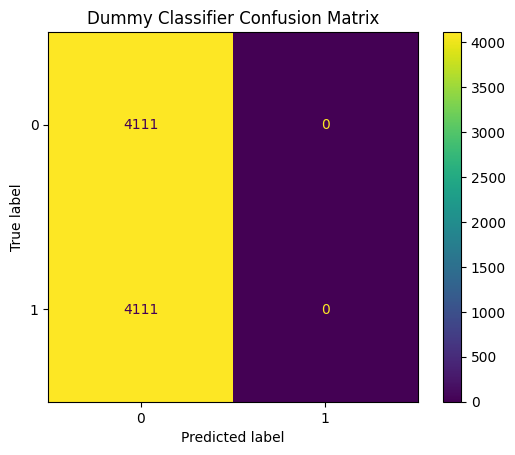

In [26]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dummy_pred
)

plt.title("Dummy Classifier Confusion Matrix")
plt.show()

## Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

In [28]:
logistic_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

In [29]:
logistic_pred = logistic_pipeline.predict(X_test)
logistic_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [30]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred
)

logistic_recall = recall_score(
    y_test,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

In [31]:
print("Logistic Regression Results")
print("---------------------------")

print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")

Logistic Regression Results
---------------------------
Accuracy : 0.7178
Precision: 0.6854
Recall   : 0.8052
F1 Score : 0.7405
ROC-AUC  : 0.7939


In [32]:
print(classification_report(y_test,logistic_pred))

              precision    recall  f1-score   support

           0       0.76      0.63      0.69      4111
           1       0.69      0.81      0.74      4111

    accuracy                           0.72      8222
   macro avg       0.72      0.72      0.72      8222
weighted avg       0.72      0.72      0.72      8222



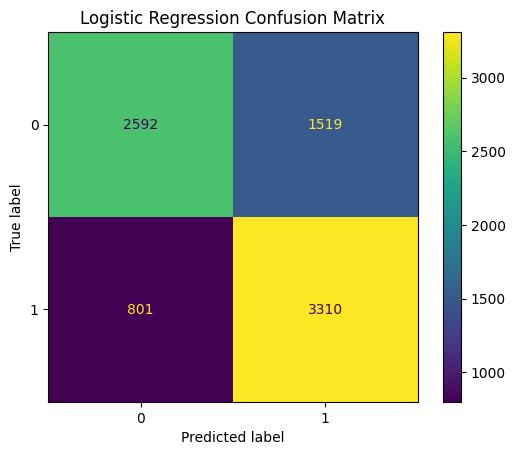

In [33]:
ConfusionMatrixDisplay.from_predictions(y_test,logistic_pred)

plt.title("Logistic Regression Confusion Matrix")

plt.show()

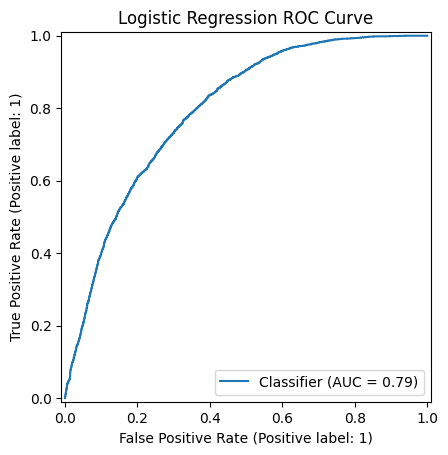

In [34]:
RocCurveDisplay.from_predictions(y_test,logistic_prob)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.show()

In [35]:
initial_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression"
    ],

    "Accuracy": [
        dummy_accuracy,
        logistic_accuracy
    ],

    "Precision": [
        dummy_precision,
        logistic_precision
    ],

    "Recall": [
        dummy_recall,
        logistic_recall
    ],

    "F1 Score": [
        dummy_f1,
        logistic_f1
    ],

    "ROC-AUC": [
        dummy_auc,
        logistic_auc
    ]
})


In [36]:
initial_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7178,0.6854,0.8052,0.7405,0.7939


### Initial Model Interpretation

The Logistic Regression model substantially outperformed the Dummy Classifier.
While the baseline achieved an ROC-AUC of 0.50, Logistic Regression achieved
an ROC-AUC of approximately 0.794 and an accuracy of 71.78%.

The model achieved a recall of 80.52%, indicating that it successfully
identified the majority of actual hit songs. Its precision was lower at
68.54%, suggesting that some non-hit songs were incorrectly classified as
hits.

The F1-score of 0.741 demonstrates a reasonable balance between precision and
recall. Overall, these results indicate that combining multiple audio
characteristics provides meaningful predictive information about hit status,
although there remains considerable room for improvement using nonlinear
machine-learning models.

## Decision Tree

In [37]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=6,
                random_state=42
            )
        )
    ]
)

In [38]:
decision_tree_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=6, random_state=42))])

In [39]:
tree_pred = decision_tree_pipeline.predict(
    X_test
)

tree_prob = decision_tree_pipeline.predict_proba(
    X_test
)[:, 1]

In [40]:
tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree_precision = precision_score(
    y_test,
    tree_pred
)

tree_recall = recall_score(
    y_test,
    tree_pred
)

tree_f1 = f1_score(
    y_test,
    tree_pred
)

tree_auc = roc_auc_score(
    y_test,
    tree_prob
)

In [41]:
print("Decision Tree Results")
print("---------------------")

print(f"Accuracy : {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall   : {tree_recall:.4f}")
print(f"F1 Score : {tree_f1:.4f}")
print(f"ROC-AUC  : {tree_auc:.4f}")

Decision Tree Results
---------------------
Accuracy : 0.7389
Precision: 0.6847
Recall   : 0.8854
F1 Score : 0.7722
ROC-AUC  : 0.8069


In [42]:
print(
    classification_report(
        y_test,
        tree_pred
    )
)

              precision    recall  f1-score   support

           0       0.84      0.59      0.69      4111
           1       0.68      0.89      0.77      4111

    accuracy                           0.74      8222
   macro avg       0.76      0.74      0.73      8222
weighted avg       0.76      0.74      0.73      8222



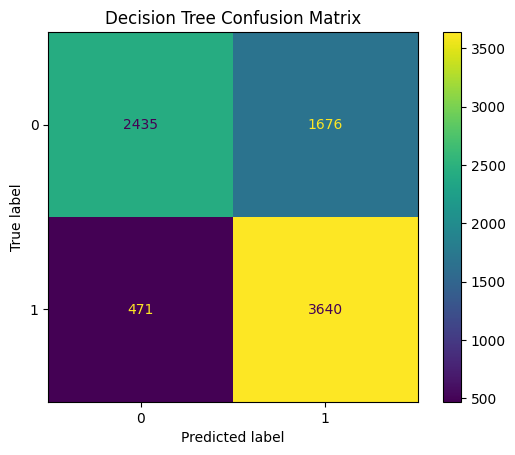

In [43]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_pred
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

## Random Forest

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [46]:
random_forest_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [47]:
rf_pred = random_forest_pipeline.predict(
    X_test
)

rf_prob = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

In [48]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred
)

rf_recall = recall_score(
    y_test,
    rf_pred
)

rf_f1 = f1_score(
    y_test,
    rf_pred
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

In [49]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.73      0.77      4111
           1       0.75      0.84      0.79      4111

    accuracy                           0.78      8222
   macro avg       0.79      0.78      0.78      8222
weighted avg       0.79      0.78      0.78      8222



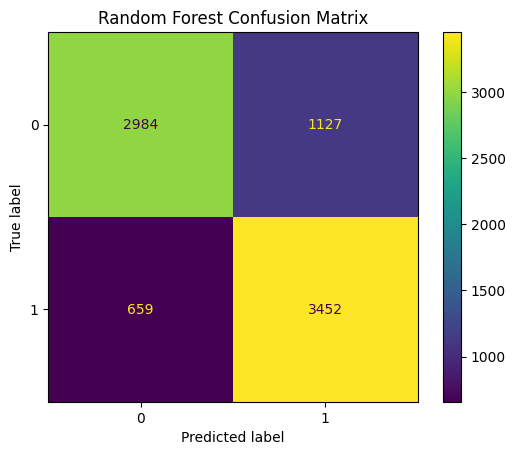

In [50]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [51]:
model_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        dummy_accuracy,
        logistic_accuracy,
        tree_accuracy,
        rf_accuracy
    ],

    "Precision": [
        dummy_precision,
        logistic_precision,
        tree_precision,
        rf_precision
    ],

    "Recall": [
        dummy_recall,
        logistic_recall,
        tree_recall,
        rf_recall
    ],

    "F1 Score": [
        dummy_f1,
        logistic_f1,
        tree_f1,
        rf_f1
    ],

    "ROC-AUC": [
        dummy_auc,
        logistic_auc,
        tree_auc,
        rf_auc
    ]
})

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7178,0.6854,0.8052,0.7405,0.7939
2,Decision Tree,0.7389,0.6847,0.8854,0.7722,0.8069
3,Random Forest,0.7828,0.7539,0.8397,0.7945,0.8639


In [52]:
model_results.sort_values(
    "ROC-AUC",
    ascending=False
).round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Random Forest,0.7828,0.7539,0.8397,0.7945,0.8639
2,Decision Tree,0.7389,0.6847,0.8854,0.7722,0.8069
1,Logistic Regression,0.7178,0.6854,0.8052,0.7405,0.7939
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000


### Model Comparison Interpretation

The tree-based models improved predictive performance compared with Logistic
Regression, suggesting that the relationship between audio characteristics and
hit status contains nonlinear patterns.

The Decision Tree achieved a recall of 88.54%, the highest among the models
tested so far. This means it identified a large proportion of actual hit songs.
However, its lower precision of 68.47% indicates that it also generated a
relatively high number of false-positive hit predictions.

Random Forest provided the strongest overall performance. It achieved an
accuracy of 78.28%, an F1-score of 0.795 and a ROC-AUC of 0.864. The improvement
over both Logistic Regression and the individual Decision Tree suggests that
combining many decision trees produces more robust predictions.

At this stage, Random Forest is the best-performing model overall, although
additional boosting-based models will be evaluated before selecting the final
model.

## XGBoost


In [53]:
from xgboost import XGBClassifier

In [54]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=5,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric="logloss",
                tree_method="hist"
            )
        )
    ]
)

In [55]:
xgb_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier',
                 XGBClassifie...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [56]:
xgb_pred = xgb_pipeline.predict(
    X_test
)

xgb_prob = xgb_pipeline.predict_proba(
    X_test
)[:, 1]

In [57]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred
)

xgb_recall = recall_score(
    y_test,
    xgb_pred
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_prob
)

In [58]:
print("XGBoost Results")
print("----------------")

print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_auc:.4f}")

XGBoost Results
----------------
Accuracy : 0.7785
Precision: 0.7441
Recall   : 0.8489
F1 Score : 0.7931
ROC-AUC  : 0.8607


In [59]:
print(
    classification_report(
        y_test,
        xgb_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.71      0.76      4111
           1       0.74      0.85      0.79      4111

    accuracy                           0.78      8222
   macro avg       0.78      0.78      0.78      8222
weighted avg       0.78      0.78      0.78      8222



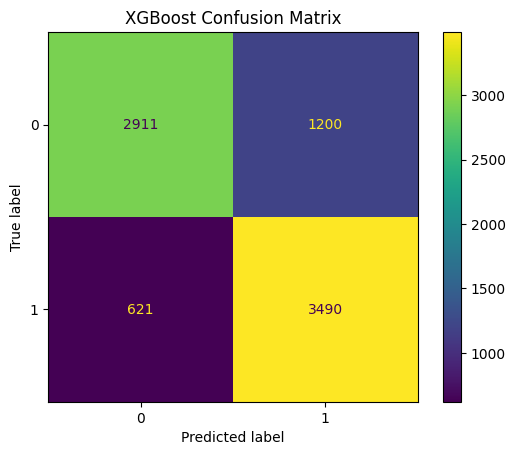

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [61]:
model_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        dummy_accuracy,
        logistic_accuracy,
        tree_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        dummy_precision,
        logistic_precision,
        tree_precision,
        rf_precision,
        xgb_precision
    ],

    "Recall": [
        dummy_recall,
        logistic_recall,
        tree_recall,
        rf_recall,
        xgb_recall
    ],

    "F1 Score": [
        dummy_f1,
        logistic_f1,
        tree_f1,
        rf_f1,
        xgb_f1
    ],

    "ROC-AUC": [
        dummy_auc,
        logistic_auc,
        tree_auc,
        rf_auc,
        xgb_auc
    ]
})

In [62]:
model_results.sort_values(
    "ROC-AUC",
    ascending=False
).round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Random Forest,0.7828,0.7539,0.8397,0.7945,0.8639
4,XGBoost,0.7785,0.7441,0.8489,0.7931,0.8607
2,Decision Tree,0.7389,0.6847,0.8854,0.7722,0.8069
1,Logistic Regression,0.7178,0.6854,0.8052,0.7405,0.7939
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000


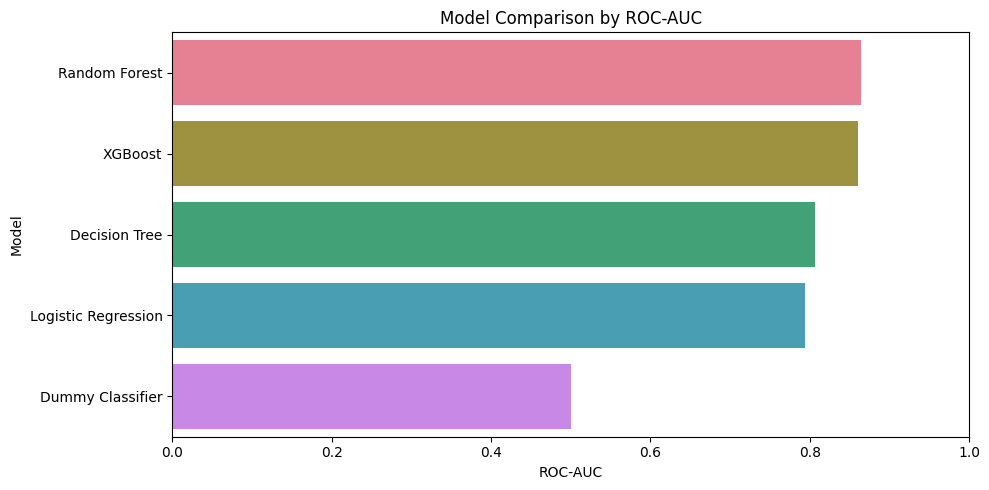

In [63]:
comparison_plot = (
    model_results
    .sort_values("ROC-AUC", ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_plot,
    x="ROC-AUC",
    y="Model",
    hue="Model",
    palette="husl",
    legend=False
)

plt.title("Model Comparison by ROC-AUC")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

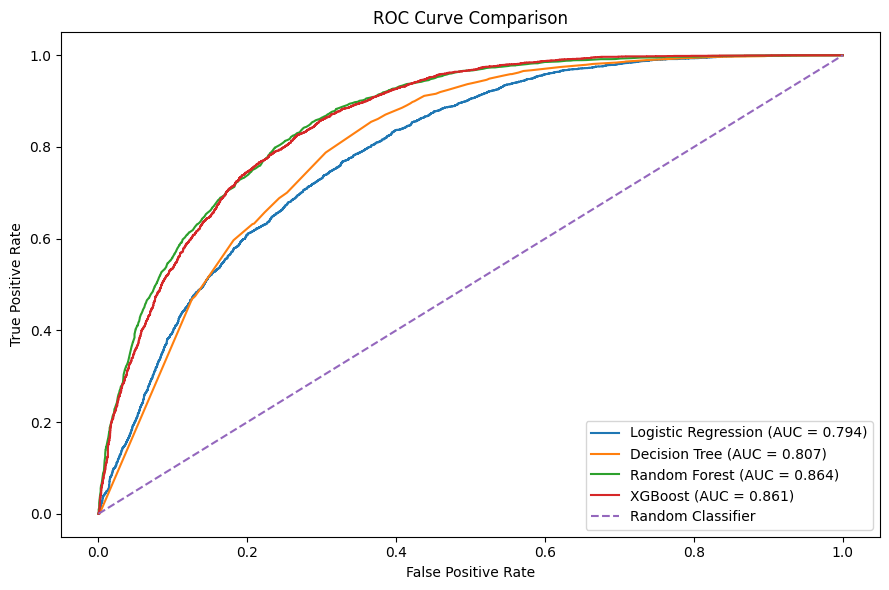

In [64]:
from sklearn.metrics import roc_curve

log_fpr, log_tpr, _ = roc_curve(y_test, logistic_prob)
tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(9, 6))

plt.plot(
    log_fpr,
    log_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    tree_fpr,
    tree_tpr,
    label=f"Decision Tree (AUC = {tree_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.tight_layout()
plt.show()

## Final Model Selection

Five classification approaches were evaluated: a Dummy Classifier,
Logistic Regression, Decision Tree, Random Forest and XGBoost.

Random Forest achieved the strongest overall test performance, with an
accuracy of 78.28%, F1-score of 0.795 and ROC-AUC of 0.864. It also
maintained a high recall of 83.97%, indicating that the model successfully
identified the majority of actual hit songs.

XGBoost produced very similar performance and achieved slightly higher
recall (84.89%). However, Random Forest achieved higher accuracy, precision,
F1-score and ROC-AUC and was therefore selected as the final predictive
model.

Extensive hyperparameter optimisation was not performed in this stage due to
computational constraints. The reported results therefore represent the
performance of the initial model configurations and provide a reproducible
baseline for future optimisation.

In [65]:
import joblib

joblib.dump(
    random_forest_pipeline,
    "hit_song_random_forest.pkl"
)

['hit_song_random_forest.pkl']

# Model Explainability

After selecting Random Forest as the final model, model explainability is used
to understand which audio characteristics contribute most strongly to its
predictions.

Two approaches are used:

1. Random Forest feature importance
2. SHAP (SHapley Additive exPlanations)

Feature importance provides a global overview of how strongly each variable
contributes to reducing prediction uncertainty across the Random Forest,
while SHAP provides more detailed information about both the magnitude and
direction of individual feature contributions.

In [66]:
rf_model = random_forest_pipeline.named_steps["classifier"]

rf_model

RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

In [67]:
fitted_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

In [68]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

feature_names

array(['num__danceability', 'num__energy', 'num__loudness',
       'num__speechiness', 'num__acousticness', 'num__instrumentalness',
       'num__liveness', 'num__valence', 'num__tempo', 'num__chorus_hit',
       'num__sections', 'num__duration_min', 'cat__key_0', 'cat__key_1',
       'cat__key_2', 'cat__key_3', 'cat__key_4', 'cat__key_5',
       'cat__key_6', 'cat__key_7', 'cat__key_8', 'cat__key_9',
       'cat__key_10', 'cat__key_11', 'cat__mode_0', 'cat__mode_1',
       'cat__time_signature_0', 'cat__time_signature_1',
       'cat__time_signature_3', 'cat__time_signature_4',
       'cat__time_signature_5'], dtype=object)

In [69]:
feature_names_clean = [
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
]

feature_names_clean

['danceability',
 'energy',
 'loudness',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'chorus_hit',
 'sections',
 'duration_min',
 'key_0',
 'key_1',
 'key_2',
 'key_3',
 'key_4',
 'key_5',
 'key_6',
 'key_7',
 'key_8',
 'key_9',
 'key_10',
 'key_11',
 'mode_0',
 'mode_1',
 'time_signature_0',
 'time_signature_1',
 'time_signature_3',
 'time_signature_4',
 'time_signature_5']

### Random Forest Feature Importance

In [70]:
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names_clean,
    "Importance": rf_model.feature_importances_
})

In [71]:
rf_feature_importance = (
    rf_feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

rf_feature_importance

,Feature,Importance
0,instrumentalness,0.164138
1,acousticness,0.105809
2,danceability,0.102869
3,energy,0.080809
4,loudness,0.072562
5,speechiness,0.071601
6,duration_min,0.070462
7,valence,0.067765
8,tempo,0.052309
9,liveness,0.050132


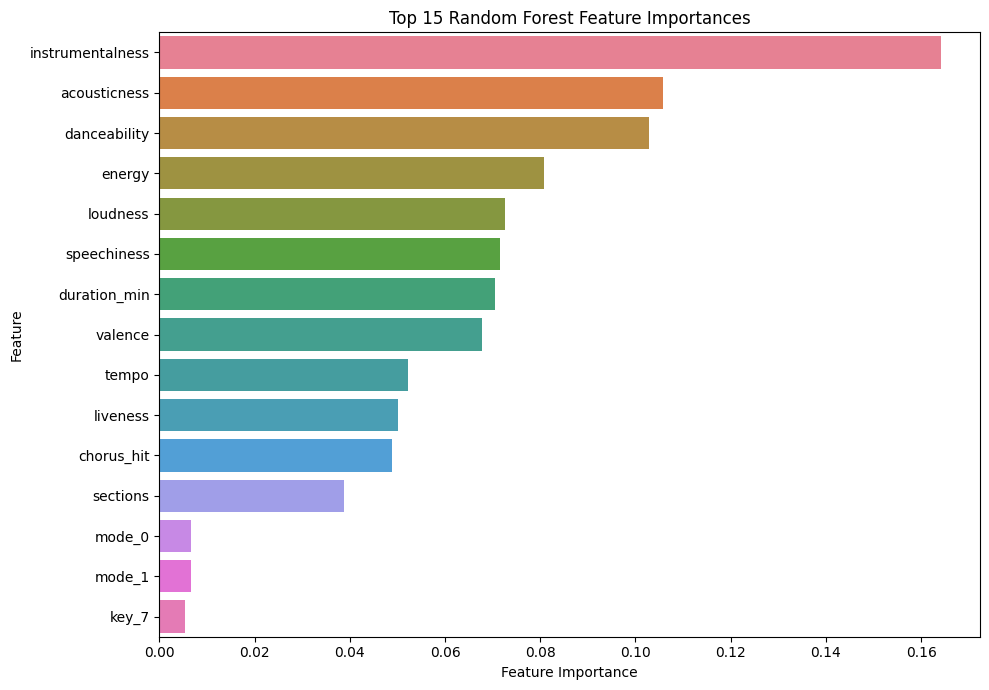

In [72]:
top_features = rf_feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="husl",
    legend=False
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [73]:
!pip install shap -q

In [74]:
import shap

In [75]:
X_test_transformed = fitted_preprocessor.transform(
    X_test
)

In [76]:
X_test_transformed.shape

(8222, 31)

In [77]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_test_transformed.shape[0],
    size=200,
    replace=False
)

X_shap = X_test_transformed[sample_indices]

if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (200, 31)


In [78]:
explainer = shap.TreeExplainer(rf_model)

In [79]:
shap_values = explainer.shap_values(
    X_shap,
    approximate=True,
    check_additivity=False
)

In [80]:
type(shap_values)
np.array(shap_values).shape

(200, 31, 2)

In [81]:
shap_array = np.array(shap_values)

if isinstance(shap_values, list):
    shap_hit = shap_values[1]

elif shap_array.ndim == 3:
    shap_hit = shap_array[:, :, 1]

else:
    shap_hit = shap_array

In [82]:
shap_hit.shape

(200, 31)

### SHAP Sampling

To reduce computational cost, global SHAP analysis was performed on a
reproducible random sample of 200 observations from the test set. Approximate
TreeSHAP values were used for the global analysis, while the individual-song
explanation was calculated separately.

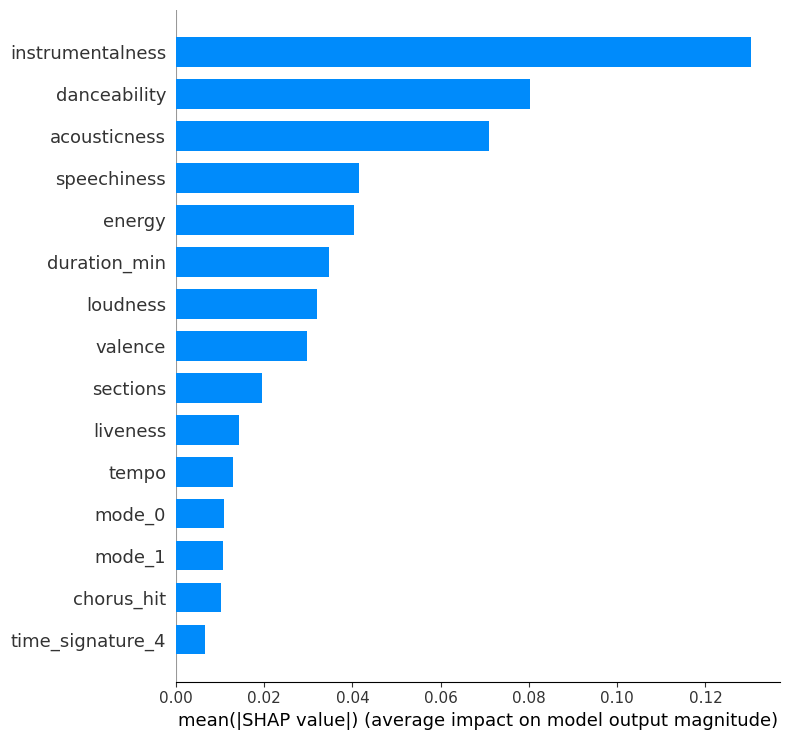

In [83]:
shap.summary_plot(
    shap_hit,
    X_shap,
    feature_names=feature_names_clean,
    plot_type="bar",
    max_display=15
)

### Understanding SHAP Values

A positive SHAP value indicates that a feature pushed the model's prediction
toward the Hit class, while a negative SHAP value indicates that the feature
pushed the prediction toward the Non-Hit class.

The SHAP summary plot also displays feature values, allowing both feature
importance and the direction of influence to be examined.

This is particularly useful because Random Forest can capture nonlinear
relationships that are not visible through simple correlations alone.

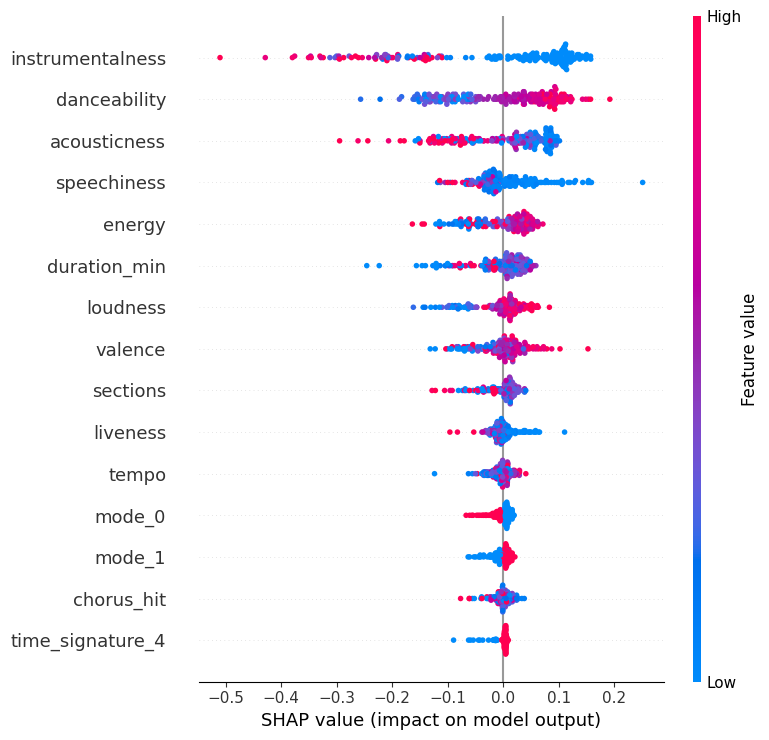

In [84]:
shap.summary_plot(
    shap_hit,
    X_shap,
    feature_names=feature_names_clean,
    max_display=15
)

### SHAP Interpretation

The SHAP analysis provides insight into both the importance and direction of
the features influencing Random Forest predictions.

Instrumentalness emerged as the strongest predictor. High instrumentalness
values generally produced negative SHAP values, pushing predictions toward the
Non-Hit class, while low instrumentalness tended to push predictions toward
Hit. This is consistent with the exploratory analysis, which found substantially
lower instrumentalness among hit songs.

Danceability showed the opposite pattern. Higher danceability values generally
pushed predictions toward Hit, while lower values tended to support Non-Hit
predictions. Higher energy, loudness and valence also generally contributed
positively toward Hit predictions.

Acousticness displayed a strong negative pattern, with highly acoustic songs
more frequently pushed toward the Non-Hit class. Higher speechiness and longer
song duration also tended to contribute negatively, although their effects were
less pronounced.

Tempo showed relatively small SHAP values concentrated around zero, indicating
that tempo contributes comparatively little to the model's predictions.

Overall, the SHAP analysis supports many of the patterns identified during
exploratory analysis while also demonstrating that the Random Forest combines
multiple characteristics rather than relying on a single feature.

### EDA vs Machine-Learning Findings

Several important relationships identified during exploratory analysis were
also learned by the Random Forest model:

- **Instrumentalness:** Higher values were associated with non-hits and pushed
  model predictions toward Non-Hit.
- **Danceability:** Higher values were associated with hits and pushed
  predictions toward Hit.
- **Acousticness:** Higher values were associated with non-hits and generally
  reduced predicted hit potential.
- **Energy:** Higher values were more common among hits and generally increased
  predicted hit potential.
- **Loudness:** Louder songs tended to receive stronger contributions toward
  Hit predictions.
- **Valence:** Higher values generally contributed positively toward Hit
  predictions.
- **Tempo:** Both EDA and SHAP indicated relatively weak predictive influence.

The consistency between exploratory analysis and model explainability increases
confidence that the model is learning meaningful patterns within the dataset
rather than relying entirely on arbitrary relationships.

### Individual Song Explanation

To demonstrate local model explainability, one observation from the test set
is selected and its prediction is examined using SHAP. This shows which
features pushed the individual prediction toward Hit or Non-Hit.

In [85]:
song_index = 0

song = X_test.iloc[[song_index]]

song

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,chorus_hit,sections,duration_min
8081,0.238,0.965,10,-4.66,0,0.119,0.000078,0.0709,0.151,0.175,149.623,4,26.78544,16,5.868667


In [86]:
song_prediction = random_forest_pipeline.predict(
    song
)[0]

song_probability = random_forest_pipeline.predict_proba(
    song
)[0, 1]

actual_label = y_test.iloc[song_index]

print(
    "Actual:",
    "Hit" if actual_label == 1 else "Non-Hit"
)

print(
    "Prediction:",
    "Hit" if song_prediction == 1 else "Non-Hit"
)

print(
    f"Model-estimated Hit Probability: {song_probability:.2%}"
)

Actual: Non-Hit
Prediction: Non-Hit
Model-estimated Hit Probability: 2.67%


In [87]:
song_transformed = fitted_preprocessor.transform(
    song
)

if hasattr(song_transformed, "toarray"):
    song_transformed = song_transformed.toarray()

In [88]:
song_shap_values = explainer.shap_values(
    song_transformed
)

In [89]:
song_shap_array = np.array(song_shap_values)

if isinstance(song_shap_values, list):
    song_shap_hit = song_shap_values[1][0]

elif song_shap_array.ndim == 3:
    song_shap_hit = song_shap_array[0, :, 1]

else:
    song_shap_hit = song_shap_array[0]

In [90]:
song_explanation = pd.DataFrame({
    "Feature": feature_names_clean,
    "SHAP Value": song_shap_hit
})

# Create absolute magnitude of each SHAP contribution
song_explanation["Absolute Impact"] = (
    song_explanation["SHAP Value"].abs()
)

# Sort by strongest contribution
song_explanation = (
    song_explanation
    .sort_values(
        by="Absolute Impact",
        ascending=False
    )
    .reset_index(drop=True)
)

song_explanation.head(10)

,Feature,SHAP Value,Absolute Impact
0,danceability,-0.140507,0.140507
1,instrumentalness,-0.083064,0.083064
2,energy,-0.074928,0.074928
3,acousticness,-0.074192,0.074192
4,speechiness,-0.047401,0.047401
5,valence,-0.041310,0.041310
6,loudness,0.016426,0.016426
7,duration_min,-0.016346,0.016346
8,key_10,0.011302,0.011302
9,mode_0,-0.007116,0.007116


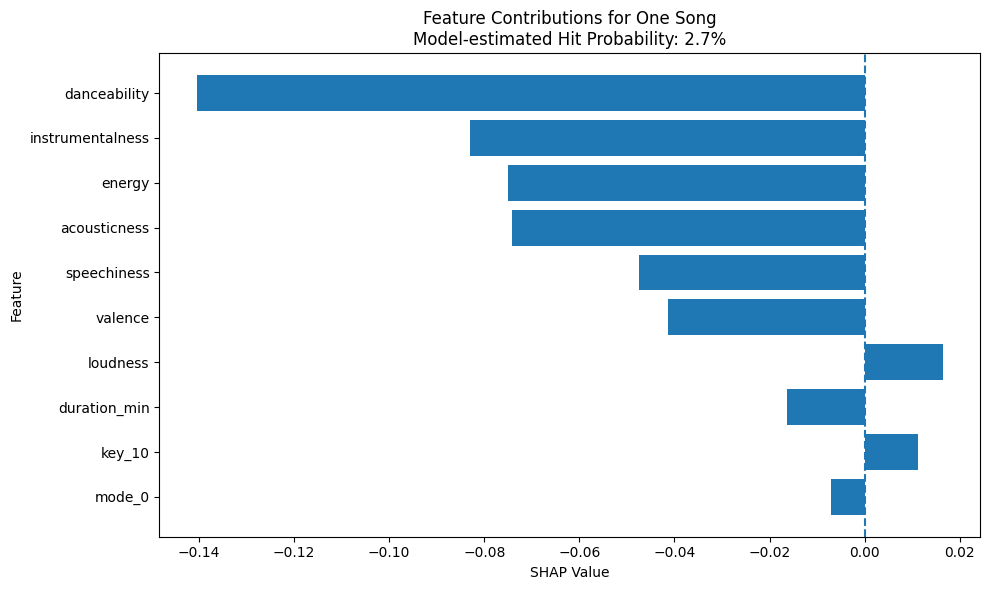

In [91]:
song_top = song_explanation.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    song_top["Feature"],
    song_top["SHAP Value"]
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title(
    f"Feature Contributions for One Song\n"
    f"Model-estimated Hit Probability: {song_probability:.1%}"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Save Results

In [92]:
model_results.to_csv(
    "model_comparison_results.csv",
    index=False
)
rf_feature_importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

# Final Conclusion

This project investigated whether audio and structural characteristics of songs
can be used to predict Billboard hit status.

Five classification approaches were evaluated: a Dummy Classifier, Logistic
Regression, Decision Tree, Random Forest and XGBoost. Random Forest achieved
the strongest overall performance, with:

- **Accuracy:** 78.28%
- **Precision:** 75.39%
- **Recall:** 83.97%
- **F1-score:** 79.45%
- **ROC-AUC:** 86.39%

XGBoost performed very similarly and achieved slightly higher recall, but
Random Forest provided the strongest overall balance across the evaluation
metrics and was selected as the final model.

Model explainability showed that **instrumentalness, acousticness and
danceability** were among the most influential predictors. SHAP analysis
showed that low instrumentalness and acousticness, together with higher
danceability, energy and loudness, generally pushed predictions toward the
Hit class.

These findings were broadly consistent with the exploratory analysis. However,
substantial overlap remained between hit and non-hit songs, demonstrating that
commercial success cannot be explained by audio characteristics alone.

Overall, the project demonstrates that musical characteristics contain
meaningful predictive information about hit status, while also highlighting
the importance of external factors that are not represented in the dataset.

# Limitations

Several limitations should be considered when interpreting the results.

1. **Audio features alone do not determine commercial success.** Factors such
   as artist popularity, marketing, record-label support, playlist placement,
   social media trends and cultural events are not included.

2. **The dataset is artificially balanced.** Hits and non-hits are represented
   equally, so the 50% hit proportion does not represent the real-world
   probability that a released song becomes a Billboard hit.

3. **Historical changes in music may affect model generalisation.** The dataset
   covers multiple decades, and the characteristics of successful songs have
   changed substantially over time.

4. **The model identifies associations rather than causal relationships.**
   Features such as danceability or instrumentalness being associated with hit
   status does not mean changing those characteristics will cause a song to
   become successful.

5. **Extensive hyperparameter optimisation was not completed due to
   computational constraints.** Therefore, additional optimisation could
   potentially improve predictive performance.

6. **Random train/test splitting does not fully simulate future prediction.**
   A temporal validation strategy could provide a more realistic test by
   training on earlier decades and evaluating performance on later music.
7. **The held-out test set was also used to compare candidate models and
   select the final model.** A more rigorous production workflow would use
   cross-validation or a separate validation set for model selection and
   reserve an untouched test set for the final performance estimate.

# Future Improvements

Future versions of the project could extend the analysis by:

- Performing more extensive hyperparameter optimisation.
- Using temporal validation to test whether historical songs can predict
  hits from later decades.
- Incorporating artist popularity, release information and streaming metrics.
- Adding lyrical features using natural language processing.
- Investigating genre-specific hit prediction.
- Calibrating model probabilities to produce more reliable hit-probability
  estimates.
- Deploying the trained model through an interactive application.
- Comparing additional boosting algorithms such as LightGBM and CatBoost.